## INF17407 - Meta-heurísticas
## Algorítmo Grasp para o problema de roteamento de veículos
### João Vitor Soares dos Santos e Pedro Quedevez


Neste notebook, vamos resolver o **Problema de Roteamento de Veículos Capacitado (CVRP)** usando as instâncias dos conjuntos A, B e F da biblioteca CVRPLIB. Os arquivos de entrada estão no diretório instâncias, o notebook abre cada arquivo `.vrp`, pega coordenadas, demandas, depósito e capacidade, e tenta encontrar o ótimo informado no próprio `.vrp`.

A solução é construída com GRASP, melhorada por busca local e conferida para garantir que todos os clientes foram atendidos, sem ferir nenhuma restrição (nesse caso a capacidade dos caminhões/veículos). As distâncias `EUC_2D` foram arredondadas.

Execute as células na ordem. As bibliotecas necessárias estão no arquivo `requirements.txt`, na raiz do projeto; as execuções mais longas mostram barras de progresso.

No Grasp o único hiperparametro necessário para fazer a sua calibração é o alfa. Sua calibração é feita executando o algoritmo cinco vezes, com as instâncias pedidas. Com isso é definido o Alfa. Para os valores de teste para a calibração escolhemos: 0.25, 0.50 e 0.75.

In [12]:
# Vamos carregar o que precisamos para ler os arquivos, fazer contas e controlar o tempo.
from pathlib import Path
import math
import random
import re
import time

# Essas bibliotecas cuidam dos gráficos, das tabelas e das barras de progresso.
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.auto import tqdm

In [13]:
def encontrar_raiz_projeto():
    # Às vezes o notebook abre dentro de codigos/. Por isso, vamos procurando
    # a pasta instancias/ na pasta atual e também nas pastas acima dela.
    for pasta in (Path.cwd(), *Path.cwd().parents):
        if (pasta / "instancias").is_dir():
            return pasta
    # Se não encontrar, avisamos que o caminho do projeto precisa ser conferido.
    raise FileNotFoundError("Não encontrei a pasta 'instancias' nos diretórios-pai do notebook.")


# Guardamos esses caminhos para as próximas células não precisarem procurá-los de novo.
RAIZ_PROJETO = encontrar_raiz_projeto()
PASTA_INSTANCIAS = RAIZ_PROJETO / "instancias"


def leitura_da_instancia(caminho):
    # Primeiro, deixamos o caminho no formato Path, que facilita abrir o arquivo.
    caminho = Path(caminho)
    # Aqui vamos guardar os dados gerais e as seções que aparecem no arquivo .vrp.
    metadados = {}
    secoes = {}
    # Esta variável acompanha a seção que estamos lendo (coordenadas, demandas etc.).
    secao_atual = None

    # Abrimos o arquivo e passamos por cada linha para separar os dados.
    with caminho.open("r", encoding="utf-8") as arquivo:
        for linha in arquivo:
            # Tiramos os espaços extras e a quebra de linha do final.
            texto = linha.strip()
            # Linha vazia não traz informação útil, então podemos pular.
            if not texto:
                continue
            # Quando aparece EOF, chegamos ao fim do conteúdo da instância.
            if texto.upper() == "EOF":
                break
            # Esse tipo de linha marca o começo de uma seção, como coordenadas ou demandas.
            if texto.endswith("_SECTION"):
                secao_atual = texto.upper()
                secoes[secao_atual] = []
                continue
            # Se estamos dentro de uma seção, separamos os campos e guardamos a linha.
            if secao_atual is not None:
                secoes[secao_atual].append(texto.split())
            # Antes das seções ficam os metadados, geralmente escritos como CHAVE: VALOR.
            elif ":" in texto:
                chave, valor = texto.split(":", 1)
                metadados[chave.strip().upper()] = valor.strip()
            else:
                # Algumas instâncias escrevem os metadados sem os dois-pontos.
                partes = texto.split(None, 1)
                if len(partes) == 2:
                    metadados[partes[0].strip().upper()] = partes[1].strip()

    # Sem coordenadas e demandas, não temos o necessário para montar as rotas.
    if "NODE_COORD_SECTION" not in secoes or "DEMAND_SECTION" not in secoes:
        raise ValueError("A instância precisa conter NODE_COORD_SECTION e DEMAND_SECTION.")

    # Para cada nó, guardamos suas coordenadas no formato (x, y).
    coordenadas = {
        int(linha[0]): (float(linha[1]), float(linha[2]))
        for linha in secoes["NODE_COORD_SECTION"] if len(linha) >= 3
    }

    # Agora associamos cada nó à quantidade que ele precisa receber.
    demandas = {
        int(linha[0]): int(float(linha[1]))
        for linha in secoes["DEMAND_SECTION"] if len(linha) >= 2
    }

    # Procuramos o depósito. O -1 que pode aparecer na seção só indica o fim dela.
    secao_deposito = secoes.get("DEPOT_SECTION", [])
    depositos = [int(linha[0]) for linha in secao_deposito if linha and int(linha[0]) != -1]
    if not depositos:
        raise ValueError("A instância não informa o depósito em DEPOT_SECTION.")

    # Usamos o primeiro depósito informado, junto com a capacidade e os nós da instância.
    deposito = depositos[0]
    capacidade = int(metadados["CAPACITY"])
    nos = sorted(coordenadas)

    # Conferimos se todo nó tem demanda e se o depósito também aparece nas coordenadas.
    if set(nos) != set(demandas):
        raise ValueError("Os nós em NODE_COORD_SECTION e DEMAND_SECTION não coincidem.")
    if deposito not in coordenadas:
        raise ValueError("O depósito não está listado em NODE_COORD_SECTION.")

    # O nome do arquivo costuma trazer a quantidade de veículos depois de -k.
    correspondencia_k = re.search(r"-k(\d+)", caminho.stem, flags=re.IGNORECASE)
    # Se essa informação não estiver no nome, fazemos uma estimativa pela demanda total.
    numero_veiculos = int(correspondencia_k.group(1)) if correspondencia_k else math.ceil(
        sum(demandas.values()) / capacidade
    )

    # O comentário pode trazer o valor ótimo, que vamos usar depois para comparar resultados.
    comentario = metadados.get("COMMENT", "")
    correspondencia_otimo = re.search(
        r"Optimal\s+value\s*:\s*(\d+(?:\.\d+)?)", comentario, flags=re.IGNORECASE
    )
    # Se o arquivo não informar o ótimo, deixamos esse campo como None.
    valor_otimo = float(correspondencia_otimo.group(1)) if correspondencia_otimo else None
    # Se o ótimo for inteiro, guardamos como int para deixar as tabelas mais limpas.
    if valor_otimo is not None and valor_otimo.is_integer():
        valor_otimo = int(valor_otimo)

    # Todo nó que não é o depósito representa um cliente que precisa ser atendido.
    clientes = [no for no in nos if no != deposito]
    # Aproveitamos para conferir se a capacidade da frota dá conta das demandas.
    if any(demandas[cliente] > capacidade for cliente in clientes):
        raise ValueError("Há cliente com demanda maior que a capacidade do veículo.")
    if sum(demandas[cliente] for cliente in clientes) > numero_veiculos * capacidade:
        raise ValueError("A demanda total excede a capacidade da frota informada.")

    # Calculamos a distância entre cada par de nós e arredondamos como pede o EUC_2D.
    distancia = {}
    for origem in nos:
        distancia[origem] = {}
        for destino in nos:
            x1, y1 = coordenadas[origem]
            x2, y2 = coordenadas[destino]
            distancia[origem][destino] = int(math.hypot(x1 - x2, y1 - y2) + 0.5)

    # Reunimos tudo em um dicionário para as próximas etapas do GRASP usarem.
    return {
        "nome": metadados.get("NAME", caminho.stem),
        "caminho": caminho,
        "dimension": int(metadados.get("DIMENSION", len(nos))),
        "capacidade": capacidade,
        "numero_veiculos": numero_veiculos,
        "valor_otimo": valor_otimo,
        "comentario": comentario,
        "deposito": deposito,
        "coordenadas": coordenadas,
        "demandas": demandas,
        "clientes": clientes,
        "distancia": distancia,
    }


# Por fim, buscamos os arquivos .vrp dos conjuntos e deixamos os caminhos em ordem.
ARQUIVOS_INSTANCIAS = sorted(PASTA_INSTANCIAS.glob("conjunto-*/*.vrp"))
print(f"Raiz: {RAIZ_PROJETO}")
print(f"Instâncias encontradas: {len(ARQUIVOS_INSTANCIAS)}")
# Lemos a primeira instância como uma checagem rápida e mostramos um pequeno resumo.
if ARQUIVOS_INSTANCIAS:
    exemplo = leitura_da_instancia(ARQUIVOS_INSTANCIAS[0])
    print(f"Exemplo: {exemplo['nome']} | clientes: {len(exemplo['clientes'])} | veículos: {exemplo['numero_veiculos']} | capacidade: {exemplo['capacidade']} | ótimo: {exemplo['valor_otimo']}")

Raiz: /home/joao/meta_heuristicas
Instâncias encontradas: 53
Exemplo: A-n32-k5 | clientes: 31 | veículos: 5 | capacidade: 100 | ótimo: 784


In [14]:
# Aqui calculamos o custo da rota, contando a saída e a volta ao depósito.
def custo_rota(rota, instancia):
    deposito = instancia["deposito"]
    sequencia = [deposito, *rota, deposito]
    distancia = instancia["distancia"]
    # Somamos as distâncias entre cada par de pontos vizinhos.
    return sum(distancia[a][b] for a, b in zip(sequencia, sequencia[1:]))


# O custo total da solução é simplesmente a soma dos custos das rotas.
def funcao_objetivo(solucao, instancia):
    return sum(custo_rota(rota, instancia) for rota in solucao)


# Antes de aceitar uma solução, conferimos se ela respeita as regras do problema.
def validar_solucao(solucao, instancia):
    motivos = []
    clientes_roteados = [cliente for rota in solucao for cliente in rota]
    esperados = set(instancia["clientes"])

    # Primeiro, vemos se a quantidade de rotas cabe na frota disponível.
    if len(solucao) > instancia["numero_veiculos"]:
        motivos.append("número de rotas maior que o número de veículos")
    # Cada cliente precisa aparecer uma vez só, e ninguém pode ficar de fora.
    if len(clientes_roteados) != len(set(clientes_roteados)):
        motivos.append("há cliente visitado mais de uma vez")
    if set(clientes_roteados) != esperados:
        motivos.append("há cliente faltando ou nó inválido")

    # Também conferimos se a carga de cada veículo respeita o limite de capacidade.
    for indice, rota in enumerate(solucao, start=1):
        carga = sum(instancia["demandas"][cliente] for cliente in rota)
        if carga > instancia["capacidade"]:
            motivos.append(f"rota {indice} excede a capacidade ({carga})")
    # Se a lista de motivos ficou vazia, a solução passou por todas as verificações.
    return not motivos, motivos

In [15]:
# Aqui buscamos a posição que aumenta menos o custo ao inserir um cliente.
def _melhor_insercao(rota, cliente, instancia):
    melhor_delta = math.inf
    melhor_posicao = 0
    # Testamos os espaços entre os clientes, inclusive o início e o fim da rota.
    for posicao in range(len(rota) + 1):
        candidata = rota[:posicao] + [cliente] + rota[posicao:]
        delta = custo_rota(candidata, instancia) - custo_rota(rota, instancia)
        if delta < melhor_delta:
            melhor_delta, melhor_posicao = delta, posicao
    return melhor_delta, melhor_posicao


# Se a construção não conseguir encaixar os clientes, tentamos uma distribuição completa.
def _empacotamento_exato(clientes, instancia, limite_nos=250000):
    capacidade = instancia["capacidade"]
    k = instancia["numero_veiculos"]
    demandas = instancia["demandas"]
    # Começar pelos clientes com maior demanda costuma facilitar a distribuição.
    ordenados = sorted(clientes, key=lambda cliente: demandas[cliente], reverse=True)
    rotas = [[] for _ in range(k)]
    cargas = [0] * k
    estados_falhos = set()
    nos_visitados = [0]

    def alocar(indice):
        nos_visitados[0] += 1
        # Colocamos um limite na busca para ela não ficar rodando sem fim.
        if nos_visitados[0] > limite_nos:
            return False
        # Se chegamos até aqui, todos os clientes já foram distribuídos.
        if indice == len(ordenados):
            return True
        # Guardamos os casos que já falharam para não testá-los de novo.
        estado = (indice, tuple(sorted(cargas, reverse=True)))
        if estado in estados_falhos:
            return False

        cliente = ordenados[indice]
        demanda = demandas[cliente]
        cargas_ja_testadas = set()
        # Tentamos primeiro os veículos que já estão mais carregados.
        for veiculo in sorted(range(k), key=lambda i: cargas[i], reverse=True):
            # Veículos com a mesma carga são equivalentes para esta tentativa.
            if cargas[veiculo] in cargas_ja_testadas:
                continue
            cargas_ja_testadas.add(cargas[veiculo])
            if cargas[veiculo] + demanda <= capacidade:
                cargas[veiculo] += demanda
                rotas[veiculo].append(cliente)
                if alocar(indice + 1):
                    return True
                # Esta tentativa não deu certo, então desfazemos a alocação.
                rotas[veiculo].pop()
                cargas[veiculo] -= demanda
                if cargas[veiculo] == 0:
                    break
        estados_falhos.add(estado)
        return False

    if not alocar(0):
        raise RuntimeError(
            "Não foi possível encontrar uma partição viável dentro do limite de busca; "
            "verifique capacidade, número de veículos e demanda total."
        )

    # Com os clientes distribuídos, organizamos cada rota para começar com um custo menor.
    rotas_ordenadas = []
    for rota in rotas:
        ordem = []
        for cliente in rota:
            _, posicao = _melhor_insercao(ordem, cliente, instancia)
            ordem.insert(posicao, cliente)
        if ordem:
            rotas_ordenadas.append(ordem)
    return rotas_ordenadas


# Agora montamos uma solução inicial usando a RCL (lista restrita de candidatos).
def algoritmo_construtivo(alfa, instancia, rng):
    if not 0 <= alfa <= 1:
        raise ValueError("alfa deve estar entre 0 e 1.")
    k = instancia["numero_veiculos"]
    capacidade = instancia["capacidade"]
    demandas = instancia["demandas"]
    rotas = [[] for _ in range(k)]
    cargas = [0] * k
    # Atendemos primeiro os clientes com demandas maiores para facilitar os encaixes.
    restantes = sorted(instancia["clientes"], key=lambda c: demandas[c], reverse=True)

    while restantes:
        # Para trazer um pouco de aleatoriedade, sorteamos entre até três demandas maiores.
        candidatos_clientes = restantes[:min(3, len(restantes))]
        cliente = rng.choice(candidatos_clientes)
        candidatos = []
        # Guardamos as inserções possíveis nos veículos que ainda têm capacidade.
        for veiculo, rota in enumerate(rotas):
            if cargas[veiculo] + demandas[cliente] <= capacidade:
                delta, posicao = _melhor_insercao(rota, cliente, instancia)
                candidatos.append((delta, veiculo, posicao))

        # Se não houver opção viável, usamos a busca de distribuição como alternativa.
        if not candidatos:
            return _empacotamento_exato(instancia["clientes"], instancia)

        # O alfa define até onde aceitamos opções um pouco mais caras que a melhor.
        menor = min(c[0] for c in candidatos)
        maior = max(c[0] for c in candidatos)
        limite_rcl = menor + alfa * (maior - menor)
        rcl = [c for c in candidatos if c[0] <= limite_rcl]
        # Dentre as opções da lista, escolhemos uma ao acaso.
        _, veiculo, posicao = rng.choice(rcl)
        rotas[veiculo].insert(posicao, cliente)
        cargas[veiculo] += demandas[cliente]
        restantes.remove(cliente)

    # No final, removemos os veículos que não precisaram fazer nenhuma entrega.
    return [rota for rota in rotas if rota]

In [16]:
# Busca local Best-Improvement: avalia todas as vizinhanças e aplica a maior redução encontrada.
def busca_local_best_improvement(solucao, instancia, max_movimentos=100):
    k = instancia["numero_veiculos"]
    rotas = [rota[:] for rota in solucao]
    rotas.extend([[] for _ in range(k - len(rotas))])
    demandas = instancia["demandas"]
    capacidade = instancia["capacidade"]

    for _ in range(max_movimentos):
        custos = [custo_rota(rota, instancia) for rota in rotas]
        cargas = [sum(demandas[cliente] for cliente in rota) for rota in rotas]
        melhor_delta = 0
        melhor_movimento = None

        for i, rota in enumerate(rotas):
            for inicio in range(len(rota) - 1):
                for fim in range(inicio + 1, len(rota)):
                    nova = rota[:inicio] + list(reversed(rota[inicio:fim + 1])) + rota[fim + 1:]
                    delta = custo_rota(nova, instancia) - custos[i]
                    if delta < melhor_delta:
                        melhor_delta = delta
                        melhor_movimento = ("rota", i, nova)

        for origem, rota_origem in enumerate(rotas):
            for indice, cliente in enumerate(rota_origem):
                sem_cliente = rota_origem[:indice] + rota_origem[indice + 1:]
                for destino, rota_destino in enumerate(rotas):
                    if destino != origem and cargas[destino] + demandas[cliente] > capacidade:
                        continue
                    base_destino = sem_cliente if destino == origem else rota_destino
                    for posicao in range(len(base_destino) + 1):
                        nova_destino = base_destino[:posicao] + [cliente] + base_destino[posicao:]
                        if destino == origem:
                            if nova_destino == rota_origem:
                                continue
                            delta = custo_rota(nova_destino, instancia) - custos[origem]
                            movimento = ("rota", origem, nova_destino)
                        else:
                            delta = (custo_rota(sem_cliente, instancia)
                                     + custo_rota(nova_destino, instancia)
                                     - custos[origem] - custos[destino])
                            movimento = ("duas_rotas", origem, destino, sem_cliente, nova_destino)
                        if delta < melhor_delta:
                            melhor_delta = delta
                            melhor_movimento = movimento

        for i in range(len(rotas)):
            for j in range(i + 1, len(rotas)):
                for pos_i, cliente_i in enumerate(rotas[i]):
                    for pos_j, cliente_j in enumerate(rotas[j]):
                        nova_carga_i = cargas[i] - demandas[cliente_i] + demandas[cliente_j]
                        nova_carga_j = cargas[j] - demandas[cliente_j] + demandas[cliente_i]
                        if nova_carga_i > capacidade or nova_carga_j > capacidade:
                            continue
                        nova_i, nova_j = rotas[i][:], rotas[j][:]
                        nova_i[pos_i], nova_j[pos_j] = cliente_j, cliente_i
                        delta = (custo_rota(nova_i, instancia) + custo_rota(nova_j, instancia)
                                 - custos[i] - custos[j])
                        if delta < melhor_delta:
                            melhor_delta = delta
                            melhor_movimento = ("duas_rotas", i, j, nova_i, nova_j)

        if melhor_movimento is None:
            break
        if melhor_movimento[0] == "rota":
            _, indice, nova_rota = melhor_movimento
            rotas[indice] = nova_rota
        else:
            _, i, j, nova_i, nova_j = melhor_movimento
            rotas[i], rotas[j] = nova_i, nova_j

    return [rota for rota in rotas if rota]


# Busca local First-Improvement: para na primeira vizinhança melhor e a aplica imediatamente.
def busca_local_first_improvement(solucao, instancia, max_movimentos=100):
    k = instancia["numero_veiculos"]
    rotas = [rota[:] for rota in solucao]
    rotas.extend([[] for _ in range(k - len(rotas))])
    demandas = instancia["demandas"]
    capacidade = instancia["capacidade"]

    for _ in range(max_movimentos):
        custos = [custo_rota(rota, instancia) for rota in rotas]
        cargas = [sum(demandas[cliente] for cliente in rota) for rota in rotas]
        primeiro_movimento = None

        for i, rota in enumerate(rotas):
            for inicio in range(len(rota) - 1):
                for fim in range(inicio + 1, len(rota)):
                    nova = rota[:inicio] + list(reversed(rota[inicio:fim + 1])) + rota[fim + 1:]
                    if custo_rota(nova, instancia) - custos[i] < 0:
                        primeiro_movimento = ("rota", i, nova)
                        break
                if primeiro_movimento is not None:
                    break
            if primeiro_movimento is not None:
                break

        if primeiro_movimento is None:
            for origem, rota_origem in enumerate(rotas):
                for indice, cliente in enumerate(rota_origem):
                    sem_cliente = rota_origem[:indice] + rota_origem[indice + 1:]
                    for destino, rota_destino in enumerate(rotas):
                        if destino != origem and cargas[destino] + demandas[cliente] > capacidade:
                            continue
                        base_destino = sem_cliente if destino == origem else rota_destino
                        for posicao in range(len(base_destino) + 1):
                            nova_destino = base_destino[:posicao] + [cliente] + base_destino[posicao:]
                            if destino == origem:
                                if nova_destino == rota_origem:
                                    continue
                                delta = custo_rota(nova_destino, instancia) - custos[origem]
                                movimento = ("rota", origem, nova_destino)
                            else:
                                delta = (custo_rota(sem_cliente, instancia)
                                         + custo_rota(nova_destino, instancia)
                                         - custos[origem] - custos[destino])
                                movimento = ("duas_rotas", origem, destino, sem_cliente, nova_destino)
                            if delta < 0:
                                primeiro_movimento = movimento
                                break
                        if primeiro_movimento is not None:
                            break
                    if primeiro_movimento is not None:
                        break
                if primeiro_movimento is not None:
                    break

        if primeiro_movimento is None:
            for i in range(len(rotas)):
                for j in range(i + 1, len(rotas)):
                    for pos_i, cliente_i in enumerate(rotas[i]):
                        for pos_j, cliente_j in enumerate(rotas[j]):
                            nova_carga_i = cargas[i] - demandas[cliente_i] + demandas[cliente_j]
                            nova_carga_j = cargas[j] - demandas[cliente_j] + demandas[cliente_i]
                            if nova_carga_i > capacidade or nova_carga_j > capacidade:
                                continue
                            nova_i, nova_j = rotas[i][:], rotas[j][:]
                            nova_i[pos_i], nova_j[pos_j] = cliente_j, cliente_i
                            delta = (custo_rota(nova_i, instancia) + custo_rota(nova_j, instancia)
                                     - custos[i] - custos[j])
                            if delta < 0:
                                primeiro_movimento = ("duas_rotas", i, j, nova_i, nova_j)
                                break
                        if primeiro_movimento is not None:
                            break
                    if primeiro_movimento is not None:
                        break
                if primeiro_movimento is not None:
                    break

        if primeiro_movimento is None:
            break
        if primeiro_movimento[0] == "rota":
            _, indice, nova_rota = primeiro_movimento
            rotas[indice] = nova_rota
        else:
            _, i, j, nova_i, nova_j = primeiro_movimento
            rotas[i], rotas[j] = nova_i, nova_j

    return [rota for rota in rotas if rota]


# A busca padrão como best-improvement.
busca_local = busca_local_best_improvement

In [17]:
# Este formato deixa o depósito visível no começo e no fim de cada rota.
def formatar_solucao(resultado, instancia):
    deposito = instancia["deposito"]
    return [
        [deposito, *rota, deposito]
        for rota in resultado["rotas"]
    ]


# GRASP clássico: construímos e melhoramos soluções, guardando a melhor que aparecer.
def grasp(instancia, alfa=0.2, max_iter=100, seed=None, max_movimentos_local=100,
          tempo_limite_seg=None, max_iter_sem_melhora=None):
    if max_iter < 1:
        raise ValueError("max_iter deve ser pelo menos 1.")
    # Com a mesma seed, conseguimos repetir o experimento com a mesma sequência aleatória.
    rng = random.Random(seed)
    inicio = time.perf_counter()
    melhor_solucao = None
    melhor_custo = math.inf
    melhor_iteracao = None
    iteracoes_sem_melhora = 0

    for iteracao in range(1, max_iter + 1):
        # Se algum limite configurado foi atingido, encerramos a busca.
        if tempo_limite_seg is not None and time.perf_counter() - inicio >= tempo_limite_seg:
            break
        if max_iter_sem_melhora is not None and iteracoes_sem_melhora >= max_iter_sem_melhora:
            break

        # Primeiro montamos uma solução; depois tentamos melhorá-la com busca local.
        solucao = algoritmo_construtivo(alfa, instancia, rng)
        solucao = busca_local(solucao, instancia, max_movimentos=max_movimentos_local)
        # Antes de comparar o custo, confirmamos que a solução atende às regras do CVRP.
        valida, motivos = validar_solucao(solucao, instancia)
        if not valida:
            raise RuntimeError("A construção/local search gerou solução inválida: " + "; ".join(motivos))
        custo = funcao_objetivo(solucao, instancia)

        # Se melhoramos o custo, guardamos a solução; se não, contamos uma iteração sem melhora.
        if custo < melhor_custo:
            melhor_solucao = [rota[:] for rota in solucao]
            melhor_custo = custo
            melhor_iteracao = iteracao
            iteracoes_sem_melhora = 0
        else:
            iteracoes_sem_melhora += 1

    # Devolvemos a melhor rota que encontramos e algumas informações sobre a execução.
    return {
        "rotas": melhor_solucao,
        "custo": melhor_custo,
        "iteracao": melhor_iteracao,
        "tempo_segundos": time.perf_counter() - inicio,
        "valida": validar_solucao(melhor_solucao, instancia)[0],
    }

In [18]:
# Estes são os valores iniciais; a célula seguinte define a grade que será usada no notebook.
ALFAS_REACTIVE_GRASP = (0.25, 0.50, 0.75)


# Aqui o algoritmo aprende quais alfas têm dado soluções melhores e passa a escolhê-los mais.
def grasp_reativo(instancia, alfas=None, max_iter=50,
                  block_iterations=2, delta=5.0, seed=None,
                  max_movimentos_local=20, tempo_limite_seg=None,
                  max_iter_sem_melhora=None):
    # Se não passarmos uma lista, usamos a grade definida na célula de parâmetros.
    if alfas is None:
        alfas = ALFAS_REACTIVE_GRASP
    if not alfas or any(not 0 <= alfa <= 1 for alfa in alfas):
        raise ValueError("Informe alfas entre 0 e 1.")
    if max_iter < 1 or block_iterations < 1 or delta <= 0:
        raise ValueError("max_iter, block_iterations e delta devem ser positivos.")

    rng = random.Random(seed)
    inicio = time.perf_counter()
    melhor_solucao = None
    melhor_custo = math.inf
    melhor_iteracao = None
    iteracoes_sem_melhora = 0
    medias_custo = {}
    bloco = []

    # Essa função é só uma forma prática de juntar construção e busca local.
    def construir_e_melhorar(alfa):
        solucao = algoritmo_construtivo(alfa, instancia, rng)
        return busca_local(solucao, instancia, max_movimentos=max_movimentos_local)

    # Antes de começar a escolha adaptativa, damos uma chance a cada alfa.
    for alfa in alfas:
        solucao = construir_e_melhorar(alfa)
        valida, motivos = validar_solucao(solucao, instancia)
        if not valida:
            raise RuntimeError("Solução inicial inviável: " + "; ".join(motivos))
        custo = funcao_objetivo(solucao, instancia)
        medias_custo[alfa] = float(custo)
        if custo < melhor_custo:
            melhor_solucao = [rota[:] for rota in solucao]
            melhor_custo = custo
            melhor_iteracao = f"inicialização (alfa={alfa:g})"

    # Transformamos os custos observados em chances de escolher cada alfa.
    def calcular_probabilidades():
        log_pesos = {
            alfa: -delta * math.log(max(medias_custo[alfa] / melhor_custo, 1.0))
            for alfa in alfas
        }
        # Esse ajuste ajuda a manter os cálculos numéricos estáveis.
        maior_log = max(log_pesos.values())
        pesos = {alfa: math.exp(log_pesos[alfa] - maior_log) for alfa in alfas}
        soma_pesos = sum(pesos.values())
        return {alfa: pesos[alfa] / soma_pesos for alfa in alfas}

    probabilidades = calcular_probabilidades()
    for iteracao in range(1, max_iter + 1):
        # Conferimos os limites de parada antes de começar mais uma rodada.
        if tempo_limite_seg is not None and time.perf_counter() - inicio >= tempo_limite_seg:
            break
        if max_iter_sem_melhora is not None and iteracoes_sem_melhora >= max_iter_sem_melhora:
            break

        # De tempos em tempos, atualizamos a média de cada alfa usado no bloco anterior.
        if iteracao > 1 and (iteracao - 1) % block_iterations == 0:
            custos_bloco = {alfa: [] for alfa in alfas}
            for alfa_observado, custo_observado in bloco:
                custos_bloco[alfa_observado].append(custo_observado)
            for alfa in alfas:
                if custos_bloco[alfa]:
                    medias_custo[alfa] = sum(custos_bloco[alfa]) / len(custos_bloco[alfa])
            probabilidades = calcular_probabilidades()
            bloco = []

        # Sorteamos um alfa conforme as chances atuais e avaliamos a solução gerada.
        alfa = rng.choices(alfas, weights=[probabilidades[a] for a in alfas], k=1)[0]
        solucao = construir_e_melhorar(alfa)
        valida, motivos = validar_solucao(solucao, instancia)
        if not valida:
            raise RuntimeError("Solução reativa inviável: " + "; ".join(motivos))
        custo = funcao_objetivo(solucao, instancia)
        bloco.append((alfa, custo))

        # Guardamos qualquer melhora; quando não há, avançamos o contador de estagnação.
        if custo < melhor_custo:
            melhor_solucao = [rota[:] for rota in solucao]
            melhor_custo = custo
            melhor_iteracao = iteracao
            iteracoes_sem_melhora = 0
        else:
            iteracoes_sem_melhora += 1

    # Além da melhor solução, devolvemos as chances finais de cada alfa.
    return {
        "rotas": melhor_solucao,
        "custo": melhor_custo,
        "iteracao": melhor_iteracao,
        "tempo_segundos": time.perf_counter() - inicio,
        "valida": validar_solucao(melhor_solucao, instancia)[0],
        "probabilidades_finais": probabilidades,
    }

In [19]:
# Também deixamos o nome em inglês disponível para chamar a mesma função.
reactive_grasp = grasp_reativo

In [20]:
# O Reactive GRASP pode escolher alfas entre 0 e 1, usando a resolução definida aqui.
PASSO_ALFA_REATIVO = 0.05
if not 0 < PASSO_ALFA_REATIVO <= 1:
    raise ValueError("PASSO_ALFA_REATIVO deve estar entre 0 e 1.")

ALFAS_REACTIVE_GRASP = tuple(
    round(indice * PASSO_ALFA_REATIVO, 2)
    for indice in range(int(1 / PASSO_ALFA_REATIVO) + 1)
)
# Garantimos que 1.0 também faça parte da lista, mesmo se o passo não dividir 1 exatamente.
if ALFAS_REACTIVE_GRASP[-1] < 1.0:
    ALFAS_REACTIVE_GRASP += (1.0,)
print(f"Alfas disponíveis para o Reactive GRASP: {ALFAS_REACTIVE_GRASP}")

Alfas disponíveis para o Reactive GRASP: (0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0)


In [21]:
# Aqui reunimos os arquivos .vrp dos conjuntos que queremos processar.
def listar_instancias(conjuntos=("conjunto-A", "conjunto-B", "conjunto-F")):
    arquivos = []
    for conjunto in conjuntos:
        arquivos.extend((PASTA_INSTANCIAS / conjunto).glob("*.vrp"))
    return sorted(arquivos)


# Essa função lê uma instância e chama o GRASP com os parâmetros escolhidos.
def resolver_instancia(caminho, alfa=0.2, max_iter=100, seed=42, max_movimentos_local=100):
    instancia = leitura_da_instancia(caminho)
    resultado = grasp(
        instancia,
        alfa=alfa,
        max_iter=max_iter,
        seed=seed,
        max_movimentos_local=max_movimentos_local,
    )
    resultado["instancia"] = instancia
    return resultado


# Essa função resolve várias instâncias e organiza os dados em uma tabela.
def executar_todas(conjuntos=("conjunto-A", "conjunto-B", "conjunto-F"), alfa=0.2,
                    max_iter=30, seed=42, max_movimentos_local=50):
    registros = []
    for indice, caminho in enumerate(listar_instancias(conjuntos)):
        resultado = resolver_instancia(
            caminho,
            alfa=alfa,
            max_iter=max_iter,
            seed=seed + indice,
            max_movimentos_local=max_movimentos_local,
        )
        instancia = resultado["instancia"]
        registros.append({
            "instancia": instancia["nome"],
            "conjunto": caminho.parent.name,
            "clientes": len(instancia["clientes"]),
            "veiculos": instancia["numero_veiculos"],
            "custo": resultado["custo"],
            "rotas": len(resultado["rotas"]),
            "valida": resultado["valida"],
            "iteracao_melhor": resultado["iteracao"],
            "tempo_segundos": resultado["tempo_segundos"],
        })
    return pd.DataFrame(registros)


## Comparação final: GRASP clássico calibrado e Reactive GRASP

Na etapa final, comparamos só duas versões: o Reactive GRASP e o GRASP clássico usando o alfa que teve melhor resultado na calibração. Para cada instância, executamos cada método cinco vezes e mostramos os custos e tempos mínimo e médio, além dos gaps em relação ao ótimo conhecido.

## Calibração manual dos parâmetros

Antes dos resultados finais, é feita a comparação dita na introdução (`0,25`), médio (`0,50`) e grande (`0,75`). Usamos as instâncias `A-n32-k5`, `A-n80-k10` e `B-n78-k10`, cinco execuções para cada combinação e um limite de 180 segundos por execução. Por fim, escolhemos o alfa com menor gap médio em relação aos ótimos conhecidos.

In [22]:
# Aqui ficam os alfas e as instâncias que vamos usar na calibração.
ALFAS_CALIBRACAO = (0.25, 0.50, 0.75)
REPETICOES_CALIBRACAO = 5
INSTANCIAS_CALIBRACAO = (
    "A-n32-k5.vrp",
    "A-n80-k10.vrp",
    "B-n78-k10.vrp",
)

# Cada execução também para ao chegar a 180 segundos.
TEMPO_MAXIMO_CALIBRACAO_SEG = 180
ITERACOES_CALIBRACAO = 50
MOVIMENTOS_CALIBRACAO = 20


# Testamos cada alfa nas instâncias escolhidas e resumimos as cinco tentativas.
def executar_calibracao_manual():
    registros = []
    for indice_instancia, nome_instancia in enumerate(INSTANCIAS_CALIBRACAO):
        # Procuramos o arquivo da instância na lista que já foi carregada.
        caminho = next(
            (arquivo for arquivo in ARQUIVOS_INSTANCIAS if arquivo.name == nome_instancia),
            None,
        )
        if caminho is None:
            raise FileNotFoundError(f"Instância de calibração não encontrada: {nome_instancia}")

        instancia = leitura_da_instancia(caminho)
        for indice_alfa, alfa in enumerate(ALFAS_CALIBRACAO):
            custos_execucao = []
            tempos_execucao = []

            # A barra mostra o andamento das cinco execuções desta combinação.
            for repeticao in tqdm(
                range(REPETICOES_CALIBRACAO),
                desc=f"Calibração GRASP α={alfa:.2f} | {nome_instancia}",
                leave=False,
            ):
                inicio = time.perf_counter()
                resultado = grasp(
                    instancia,
                    alfa=alfa,
                    max_iter=ITERACOES_CALIBRACAO,
                    # A semente muda entre instâncias, alfas e repetições.
                    seed=42 + indice_instancia * 100 + indice_alfa * 10 + repeticao,
                    max_movimentos_local=MOVIMENTOS_CALIBRACAO,
                    tempo_limite_seg=TEMPO_MAXIMO_CALIBRACAO_SEG,
                )
                tempos_execucao.append(time.perf_counter() - inicio)
                custos_execucao.append(resultado["custo"])

            # Resumimos o melhor e o desempenho médio das cinco tentativas.
            custo_minimo = min(custos_execucao)
            custo_medio = sum(custos_execucao) / len(custos_execucao)
            tempo_minimo = min(tempos_execucao)
            tempo_medio = sum(tempos_execucao) / len(tempos_execucao)
            registros.append({
                "Instância": instancia["nome"],
                "Alfa pequeno/médio/grande": alfa,
                "Fsol_otima": instancia["valor_otimo"],
                "F_meta-heuristica (min)": custo_minimo,
                "F_meta-heuristica (média)": custo_medio,
                "Tempo(s) (min)": tempo_minimo,
                "Tempo(s) (média)": tempo_medio,
                "gap(min) %": (custo_minimo / instancia["valor_otimo"] - 1) * 100,
                "gap(média) %": (custo_medio / instancia["valor_otimo"] - 1) * 100,
                "Válida": resultado["valida"],
            })

    tabela = pd.DataFrame(registros)
    # Comparamos os alfas pela média do gap; em caso de empate, usamos o custo médio.
    resumo_alfa = (
        tabela.groupby("Alfa pequeno/médio/grande", as_index=False)
        .agg(gap_medio=("gap(média) %", "mean"), custo_medio=("F_meta-heuristica (média)", "mean"))
        .sort_values(["gap_medio", "custo_medio"])
    )
    alfa_vencedor = float(resumo_alfa.iloc[0]["Alfa pequeno/médio/grande"])
    return tabela, resumo_alfa, alfa_vencedor


# Rodamos a calibração, mostramos as tabelas e guardamos o alfa escolhido.
calibracao_tabela, calibracao_resumo, ALFA_MELHOR = executar_calibracao_manual()
print("Resultados da calibração manual (5 execuções por instância e alfa):")
print(calibracao_tabela.to_string(index=False))
print("\nResumo por alfa:")
print(calibracao_resumo.to_string(index=False))
print(f"\nMelhor alfa pela menor média de gap: {ALFA_MELHOR:.2f}")

Calibração GRASP α=0.25 | A-n32-k5.vrp:   0%|          | 0/5 [00:00<?, ?it/s]

Calibração GRASP α=0.50 | A-n32-k5.vrp:   0%|          | 0/5 [00:00<?, ?it/s]

Calibração GRASP α=0.75 | A-n32-k5.vrp:   0%|          | 0/5 [00:00<?, ?it/s]

Calibração GRASP α=0.25 | A-n80-k10.vrp:   0%|          | 0/5 [00:00<?, ?it/s]

Calibração GRASP α=0.50 | A-n80-k10.vrp:   0%|          | 0/5 [00:00<?, ?it/s]

Calibração GRASP α=0.75 | A-n80-k10.vrp:   0%|          | 0/5 [00:00<?, ?it/s]

Calibração GRASP α=0.25 | B-n78-k10.vrp:   0%|          | 0/5 [00:00<?, ?it/s]

Calibração GRASP α=0.50 | B-n78-k10.vrp:   0%|          | 0/5 [00:00<?, ?it/s]

Calibração GRASP α=0.75 | B-n78-k10.vrp:   0%|          | 0/5 [00:00<?, ?it/s]

Resultados da calibração manual (5 execuções por instância e alfa):
Instância  Alfa pequeno/médio/grande  Fsol_otima  F_meta-heuristica (min)  F_meta-heuristica (média)  Tempo(s) (min)  Tempo(s) (média)  gap(min) %  gap(média) %  Válida
 A-n32-k5                       0.25         784                      808                      826.4        2.197807          2.376791    3.061224      5.408163    True
 A-n32-k5                       0.50         784                      816                      832.0        2.491699          2.588776    4.081633      6.122449    True
 A-n32-k5                       0.75         784                      819                      838.4        2.239819          2.455165    4.464286      6.938776    True
A-n80-k10                       0.25        1763                     2180                     2195.8       12.722414         13.291857   23.652864     24.549064    True
A-n80-k10                       0.50        1763                     2142              

In [23]:
# Limites finais de precisão configurados para o conjunto completo A, B e F.
ITERACOES_FINAIS = 100
MOVIMENTOS_FINAIS_LOCAL = 40
REPETICOES_FINAIS = 5


# Aqui rodamos cada método cinco vezes por instância e juntamos as métricas.
def executar_experimentos_finais(conjuntos=("conjunto-A", "conjunto-B", "conjunto-F"),
                                 alfa_classico=None, cinco_execucoes=5,
                                 max_iter=50, seed=42,
                                 max_movimentos_local=20,
                                 block_iterations=2, delta=5.0):
    if alfa_classico is None:
        alfa_classico = ALFA_MELHOR

    registros = []
    arquivos = listar_instancias(conjuntos)
    metodos = (f"GRASP alfa={alfa_classico:.2f}", "Reactive GRASP")

    for metodo in metodos:
        with tqdm(total=len(arquivos) * cinco_execucoes, desc=metodo) as progresso:
            for indice, caminho in enumerate(arquivos):
                instancia = leitura_da_instancia(caminho)
                if instancia["valor_otimo"] is None:
                    raise ValueError(
                        f"A instância {caminho.name} não possui 'Optimal value' no COMMENT."
                    )

                custos_execucao = []
                tempos_execucao = []
                for repeticao in range(cinco_execucoes):
                    seed_execucao = seed + indice * 100 + repeticao
                    if metodo == "Reactive GRASP":
                        resultado = grasp_reativo(
                            instancia,
                            alfas=ALFAS_REACTIVE_GRASP,
                            max_iter=max_iter,
                            block_iterations=block_iterations,
                            delta=delta,
                            seed=seed_execucao,
                            max_movimentos_local=max_movimentos_local,
                        )
                    else:
                        resultado = grasp(
                            instancia,
                            alfa=alfa_classico,
                            max_iter=max_iter,
                            seed=seed_execucao,
                            max_movimentos_local=max_movimentos_local,
                        )

                    if not resultado["valida"]:
                        raise RuntimeError(
                            f"Solução inviável em {caminho.name}, método={metodo}."
                        )
                    custos_execucao.append(resultado["custo"])
                    tempos_execucao.append(resultado["tempo_segundos"])
                    progresso.update(1)
                    progresso.set_postfix(instancia=instancia["nome"])

                custo_minimo = min(custos_execucao)
                custo_medio = sum(custos_execucao) / len(custos_execucao)
                tempo_minimo = min(tempos_execucao)
                tempo_medio = sum(tempos_execucao) / len(tempos_execucao)
                registros.append({
                    "Instância": instancia["nome"],
                    "Método": metodo,
                    "Fsol_otima": instancia["valor_otimo"],
                    "F_meta-heuristica (min)": custo_minimo,
                    "F_meta-heuristica (média)": custo_medio,
                    "Tempo(s) (min)": tempo_minimo,
                    "Tempo(s) (média)": tempo_medio,
                    "gap(min) %": (custo_minimo / instancia["valor_otimo"] - 1) * 100,
                    "gap(média) %": (custo_medio / instancia["valor_otimo"] - 1) * 100,
                    "Conjunto": caminho.parent.name,
                })

    return pd.DataFrame(registros)


# Essa função monta um gráfico para comparar os métodos com o ótimo conhecido.
def salvar_grafico_comparacao_final(resultados, caminho_saida=None):
    if resultados.empty:
        raise ValueError("Não há resultados finais para plotar.")
    if caminho_saida is None:
        caminho_saida = RAIZ_PROJETO / "codigos" / "comparacao_final_grasp.png"

    caminho_saida = Path(caminho_saida)
    caminho_saida.parent.mkdir(parents=True, exist_ok=True)
    grupos = sorted(resultados["Conjunto"].unique())
    metodos = sorted(resultados["Método"].unique())

    fig, eixos = plt.subplots(len(grupos), 1,
                              figsize=(18, 7 * len(grupos)), squeeze=False)
    for eixo, conjunto in zip(eixos[:, 0], grupos):
        dados = resultados[resultados["Conjunto"] == conjunto]
        instancias = sorted(dados["Instância"].unique())
        posicoes = list(range(len(instancias)))
        otimos = [dados[dados["Instância"] == nome]["Fsol_otima"].iloc[0]
                  for nome in instancias]
        eixo.plot(posicoes, otimos, color="black", marker="o", linestyle="--",
                  linewidth=2, label="Ótimo conhecido", zorder=5)

        largura = 0.8 / len(metodos)
        for indice_metodo, metodo in enumerate(metodos):
            custos = [dados[(dados["Instância"] == nome) & (dados["Método"] == metodo)]["F_meta-heuristica (min)"].iloc[0]
                      for nome in instancias]
            deslocamentos = [p - 0.4 + largura * (indice_metodo + 0.5)
                             for p in posicoes]
            eixo.bar(deslocamentos, custos, width=largura, label=metodo)

        eixo.set_title(conjunto)
        eixo.set_ylabel("Custo mínimo das 5 execuções")
        eixo.set_xticks(posicoes)
        eixo.set_xticklabels(instancias, rotation=75, ha="right", fontsize=8)
        eixo.grid(axis="y", linestyle=":", alpha=0.5)
        eixo.legend(ncol=3, fontsize=9)

    eixos[-1, 0].set_xlabel("Instância")
    fig.suptitle("Comparação final: alfa calibrado vs. Reactive GRASP", fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    fig.savefig(caminho_saida, dpi=180, bbox_inches="tight")
    plt.close(fig)
    return caminho_saida


# Executa os conjuntos exigidos pela atividade: A, B e F.
resultados_finais = executar_experimentos_finais(
    conjuntos=("conjunto-A", "conjunto-B", "conjunto-F"),
    alfa_classico=ALFA_MELHOR,
    cinco_execucoes=REPETICOES_FINAIS,
    max_iter=ITERACOES_FINAIS,
    seed=42,
    max_movimentos_local=MOVIMENTOS_FINAIS_LOCAL,
    block_iterations=2,
    delta=5.0,
)

arquivo_csv_final = RAIZ_PROJETO / "codigos" / "resultados_finais_grasp.csv"
resultados_finais.to_csv(arquivo_csv_final, index=False)
arquivo_grafico_final = salvar_grafico_comparacao_final(resultados_finais)
print(f"Alfa clássico escolhido pela calibração: {ALFA_MELHOR:.2f}")
print(f"Execuções por método/instância: {REPETICOES_FINAIS}")
print(f"Resultados CSV: {arquivo_csv_final}")
print(f"Gráfico PNG: {arquivo_grafico_final}")
resultados_finais.reset_index(drop=True)


GRASP alfa=0.25:   0%|          | 0/265 [00:00<?, ?it/s]

Reactive GRASP:   0%|          | 0/265 [00:00<?, ?it/s]

Alfa clássico escolhido pela calibração: 0.25
Execuções por método/instância: 5
Resultados CSV: /home/joao/meta_heuristicas/codigos/resultados_finais_grasp.csv
Gráfico PNG: /home/joao/meta_heuristicas/codigos/comparacao_final_grasp.png


,Instância,Método,Fsol_otima,F_meta-heuristica (min),F_meta-heuristica (média),Tempo(s) (min),Tempo(s) (média),gap(min) %,gap(média) %,Conjunto
0,A-n32-k5,GRASP alfa=0.25,784,784,806.8,4.930951,5.273186,0.000000,2.908163,conjunto-A
1,A-n33-k5,GRASP alfa=0.25,661,661,667.8,5.313765,5.413795,0.000000,1.028744,conjunto-A
2,A-n33-k6,GRASP alfa=0.25,742,742,749.0,3.985961,4.077985,0.000000,0.943396,conjunto-A
3,A-n34-k5,GRASP alfa=0.25,778,778,787.2,5.402395,5.858439,0.000000,1.182519,conjunto-A
4,A-n36-k5,GRASP alfa=0.25,799,816,826.6,5.348701,6.293179,2.127660,3.454318,conjunto-A
...,...,...,...,...,...,...,...,...,...,...
101,B-n68-k9,Reactive GRASP,1272,1382,1421.0,43.466575,44.548946,8.647799,11.713836,conjunto-B
102,B-n78-k10,Reactive GRASP,1221,1467,1487.2,59.819356,60.770318,20.147420,21.801802,conjunto-B
103,F-n135-k7,Reactive GRASP,1162,1465,1498.0,741.839693,750.371512,26.075731,28.915663,conjunto-F
104,F-n45-k4,Reactive GRASP,724,736,745.4,22.992071,24.280613,1.657459,2.955801,conjunto-F


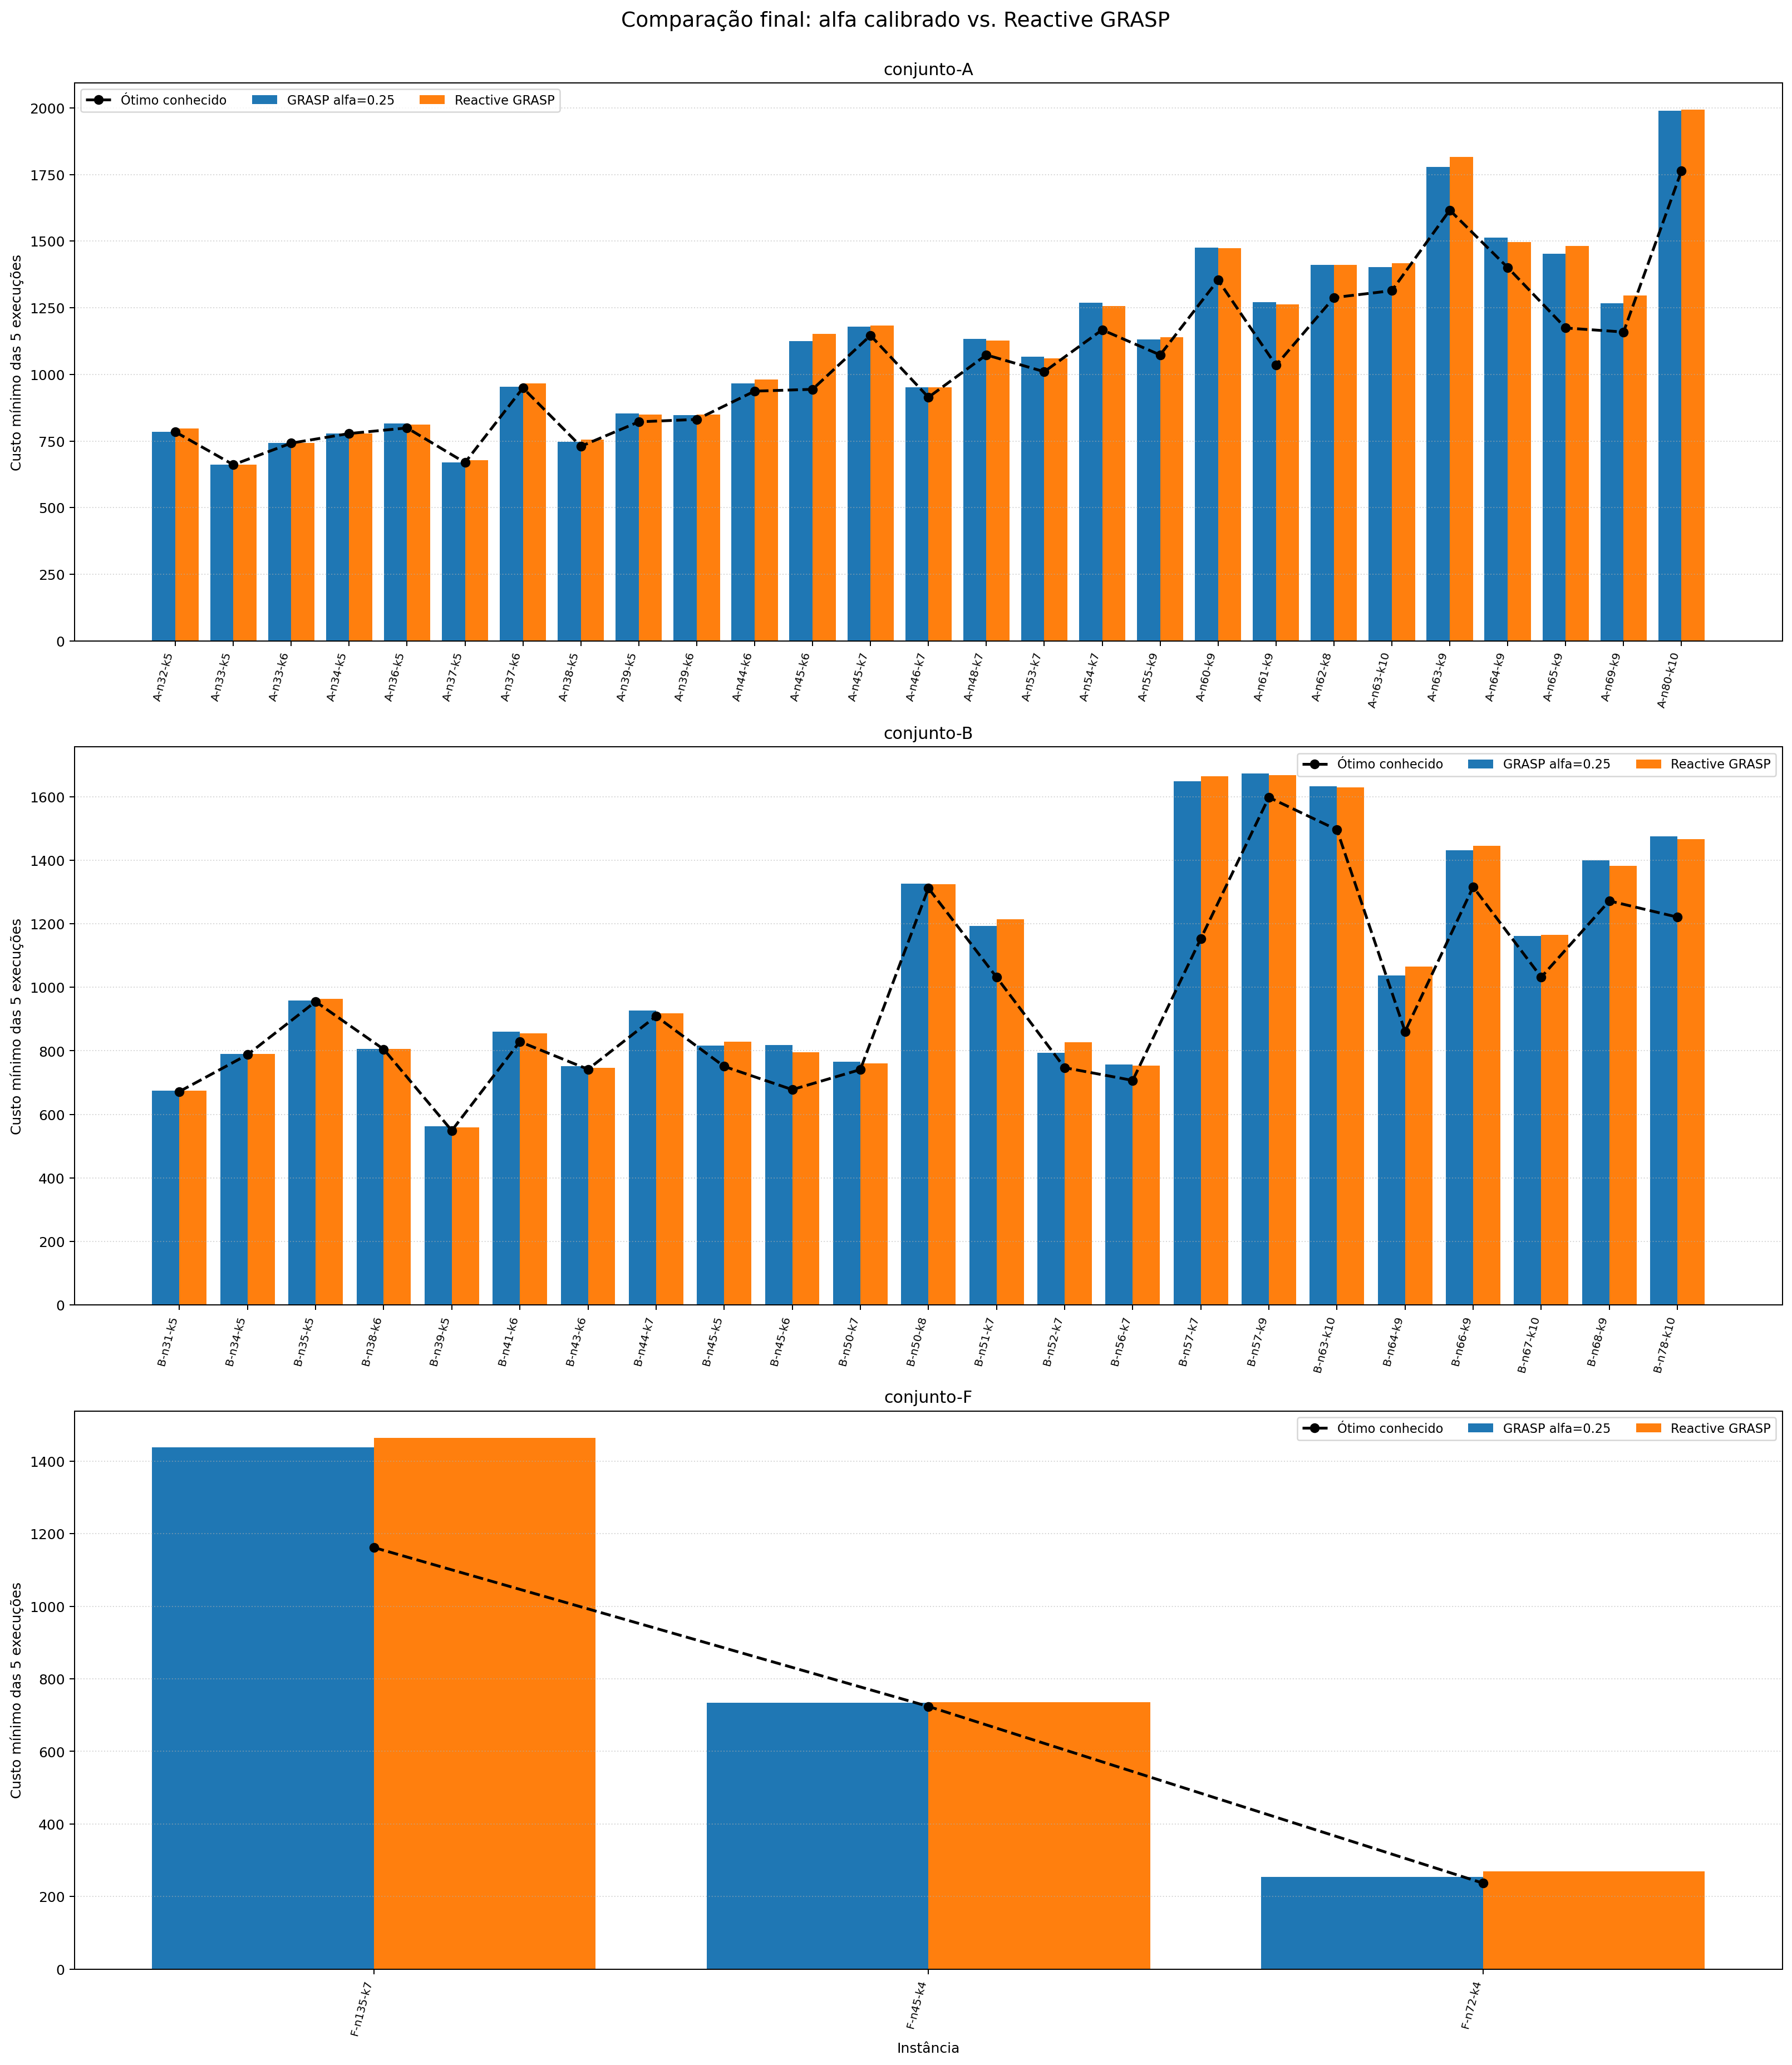

In [24]:
# Pegamos as ferramentas para mostrar a imagem direto no notebook.
from IPython.display import Image, display

# E aqui exibimos o gráfico que salvamos na célula anterior.
display(Image(filename=str(arquivo_grafico_final), width=1200))

Experimentos para convergência e TTT:   0%|          | 0/200 [00:00<?, ?it/s]

Resultados das execuções salvos em: /home/joao/meta_heuristicas/codigos/resultados_convergencia_ttt.csv


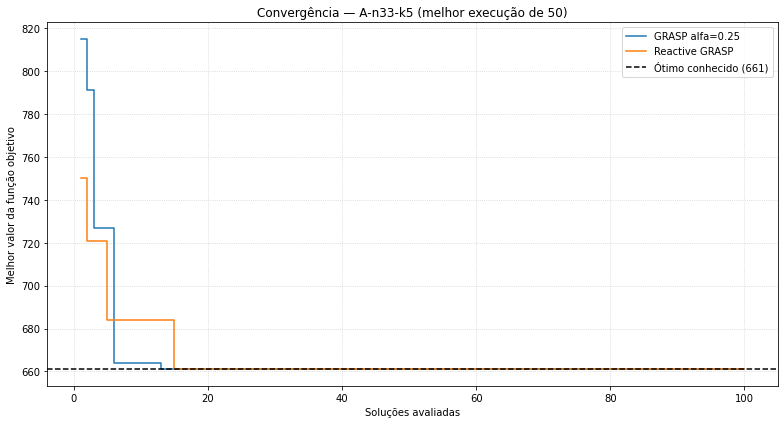

Gráfico de convergência salvo em: /home/joao/meta_heuristicas/codigos/convergencia_A-n33-k5.png


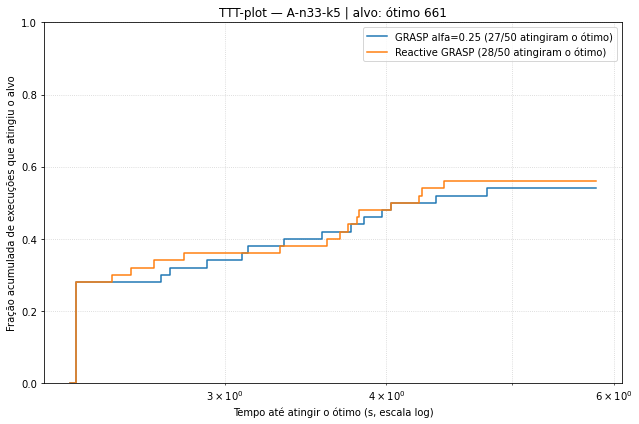

TTT-plot salvo em: /home/joao/meta_heuristicas/codigos/ttt_A-n33-k5.png


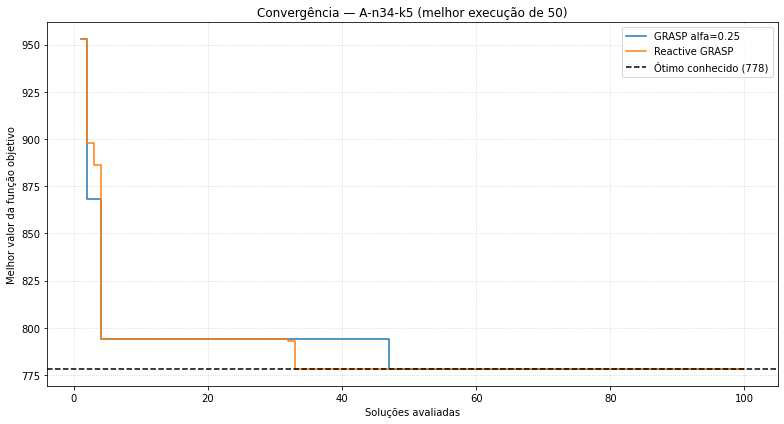

Gráfico de convergência salvo em: /home/joao/meta_heuristicas/codigos/convergencia_A-n34-k5.png


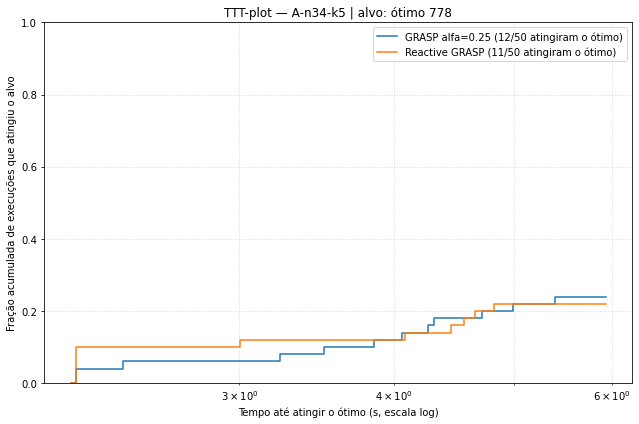

TTT-plot salvo em: /home/joao/meta_heuristicas/codigos/ttt_A-n34-k5.png


,Instância,Método,execuções,melhor_custo,custo_médio,execuções_que_atingiram_ótimo,tempo_médio_s
0,A-n33-k5,GRASP alfa=0.25,50,661,664.62,27,4.912988
1,A-n33-k5,Reactive GRASP,50,661,664.58,28,4.944679
2,A-n34-k5,GRASP alfa=0.25,50,778,785.34,12,4.875019
3,A-n34-k5,Reactive GRASP,50,778,785.76,11,4.830061


In [28]:
# Comparação final: evolução e TTT para as duas instâncias escolhidas.
# Ambos os métodos usam o mesmo construtivo RCL e a busca local Best-Improvement;
# o Reactive GRASP adapta o alfa, enquanto o GRASP clássico fixa alfa=0.25.
INSTANCIAS_GRAFICOS = ("A-n33-k5.vrp", "A-n34-k5.vrp")
ALFA_GRAFICOS = 0.25
REPETICOES_TTT = 50
AVALIACOES_POR_EXECUCAO = ITERACOES_FINAIS

if len(ALFAS_REACTIVE_GRASP) >= AVALIACOES_POR_EXECUCAO:
    raise ValueError(
        "O Reactive GRASP precisa de menos alfas iniciais que avaliações totais "
        "para permitir a etapa adaptativa."
    )


def executar_grasp_com_historico(instancia, metodo, seed):
    """Executa um GRASP e registra o melhor custo após cada busca local."""
    global busca_local

    busca_local_original = busca_local
    historico = []
    melhor_custo_observado = math.inf
    inicio = time.perf_counter()

    def busca_local_monitorada(solucao, instancia_atual, max_movimentos=100):
        nonlocal melhor_custo_observado
        solucao_melhorada = busca_local_original(
            solucao,
            instancia_atual,
            max_movimentos=max_movimentos,
        )
        custo = funcao_objetivo(solucao_melhorada, instancia_atual)
        melhor_custo_observado = min(melhor_custo_observado, custo)
        historico.append({
            "Avaliacao": len(historico) + 1,
            "Melhor custo": melhor_custo_observado,
            "Tempo(s)": time.perf_counter() - inicio,
        })
        return solucao_melhorada

    busca_local = busca_local_monitorada
    try:
        if metodo == "GRASP alfa=0.25":
            resultado = grasp(
                instancia,
                alfa=ALFA_GRAFICOS,
                max_iter=AVALIACOES_POR_EXECUCAO,
                seed=seed,
                max_movimentos_local=MOVIMENTOS_FINAIS_LOCAL,
            )
        elif metodo == "Reactive GRASP":
            iteracoes_adaptativas = AVALIACOES_POR_EXECUCAO - len(ALFAS_REACTIVE_GRASP)
            resultado = grasp_reativo(
                instancia,
                alfas=ALFAS_REACTIVE_GRASP,
                max_iter=iteracoes_adaptativas,
                seed=seed,
                max_movimentos_local=MOVIMENTOS_FINAIS_LOCAL,
            )
        else:
            raise ValueError(f"Método não reconhecido: {metodo}")
    finally:
        busca_local = busca_local_original

    if len(historico) != AVALIACOES_POR_EXECUCAO:
        raise RuntimeError(
            f"Esperadas {AVALIACOES_POR_EXECUCAO} soluções avaliadas, "
            f"mas o método {metodo} produziu {len(historico)}."
        )
    return resultado, historico


resultados_execucoes_graficos = []
historicos_graficos = {}
metodos_graficos = ("GRASP alfa=0.25", "Reactive GRASP")

with tqdm(
    total=len(INSTANCIAS_GRAFICOS) * len(metodos_graficos) * REPETICOES_TTT,
    desc="Experimentos para convergência e TTT",
) as progresso_graficos:
    for nome_arquivo in INSTANCIAS_GRAFICOS:
        caminho_instancia = next(
            (arquivo for arquivo in ARQUIVOS_INSTANCIAS if arquivo.name == nome_arquivo),
            None,
        )
        if caminho_instancia is None:
            raise FileNotFoundError(f"Instância não encontrada: {nome_arquivo}")

        instancia_grafico = leitura_da_instancia(caminho_instancia)
        alvo = instancia_grafico["valor_otimo"]
        if alvo is None:
            raise ValueError(f"A instância {nome_arquivo} não informa o ótimo conhecido.")

        for metodo in metodos_graficos:
            chave = (instancia_grafico["nome"], metodo)
            historicos_graficos[chave] = []

            for repeticao in range(REPETICOES_TTT):
                seed_execucao = 2026 + repeticao
                resultado, historico = executar_grasp_com_historico(
                    instancia_grafico,
                    metodo,
                    seed=seed_execucao,
                )
                historicos_graficos[chave].append(historico)

                tempos_ate_alvo = [
                    ponto["Tempo(s)"]
                    for ponto in historico
                    if ponto["Melhor custo"] <= alvo
                ]
                resultados_execucoes_graficos.append({
                    "Instância": instancia_grafico["nome"],
                    "Método": metodo,
                    "Repetição": repeticao + 1,
                    "Ótimo conhecido": alvo,
                    "Custo final": resultado["custo"],
                    "Tempo total(s)": resultado["tempo_segundos"],
                    "Atingiu ótimo": bool(tempos_ate_alvo),
                    "Tempo até ótimo(s)": min(tempos_ate_alvo) if tempos_ate_alvo else None,
                })
                progresso_graficos.update(1)
                progresso_graficos.set_postfix(instancia=instancia_grafico["nome"], metodo=metodo)

resultados_graficos = pd.DataFrame(resultados_execucoes_graficos)
arquivo_resultados_graficos = RAIZ_PROJETO / "codigos" / "resultados_convergencia_ttt.csv"
resultados_graficos.to_csv(arquivo_resultados_graficos, index=False)
print(f"Resultados das execuções salvos em: {arquivo_resultados_graficos}")

# Para cada instância, o gráfico de convergência mostra a melhor execução de cada método.
for nome_arquivo in INSTANCIAS_GRAFICOS:
    instancia_grafico = leitura_da_instancia(
        next(arquivo for arquivo in ARQUIVOS_INSTANCIAS if arquivo.name == nome_arquivo)
    )
    nome_instancia = instancia_grafico["nome"]
    alvo = instancia_grafico["valor_otimo"]

    fig, eixo = plt.subplots(figsize=(11, 6))
    for metodo in metodos_graficos:
        execucoes = historicos_graficos[(nome_instancia, metodo)]
        melhor_historico = min(
            execucoes,
            key=lambda historico: historico[-1]["Melhor custo"],
        )
        eixo.step(
            [ponto["Avaliacao"] for ponto in melhor_historico],
            [ponto["Melhor custo"] for ponto in melhor_historico],
            where="post",
            label=metodo,
        )

    eixo.axhline(alvo, color="black", linestyle="--", label=f"Ótimo conhecido ({alvo})")
    eixo.set_title(f"Convergência — {nome_instancia} (melhor execução de {REPETICOES_TTT})")
    eixo.set_xlabel("Soluções avaliadas")
    eixo.set_ylabel("Melhor valor da função objetivo")
    eixo.grid(True, linestyle=":", alpha=0.6)
    eixo.legend()
    fig.tight_layout()
    caminho_grafico_convergencia = (
        RAIZ_PROJETO / "codigos" / f"convergencia_{nome_instancia}.png"
    )
    fig.savefig(caminho_grafico_convergencia, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Gráfico de convergência salvo em: {caminho_grafico_convergencia}")

    # O TTT mostra a fração das execuções que atingiu o ótimo conhecido até cada tempo.
    fig, eixo = plt.subplots(figsize=(9, 6))
    tempos_totais_instancia = resultados_graficos[
        resultados_graficos["Instância"] == nome_instancia
    ]["Tempo total(s)"].tolist()
    menor_tempo = min(tempos_totais_instancia)
    limite_tempo = max(tempos_totais_instancia)
    inicio_eixo_tempo = max(min(menor_tempo, limite_tempo) * 0.5, 1e-6)

    for metodo in metodos_graficos:
        dados_metodo = resultados_graficos[
            (resultados_graficos["Instância"] == nome_instancia)
            & (resultados_graficos["Método"] == metodo)
        ]
        tempos_alvo = sorted(
            dados_metodo["Tempo até ótimo(s)"].dropna().tolist()
        )
        pontos_x = [inicio_eixo_tempo]
        pontos_y = [0.0]
        for indice, tempo_alvo in enumerate(tempos_alvo, start=1):
            pontos_x.append(max(tempo_alvo, inicio_eixo_tempo * 1.01))
            pontos_y.append(indice / REPETICOES_TTT)
        pontos_x.append(max(limite_tempo, pontos_x[-1] * 1.01))
        pontos_y.append(len(tempos_alvo) / REPETICOES_TTT)
        eixo.step(
            pontos_x,
            pontos_y,
            where="post",
            label=f"{metodo} ({len(tempos_alvo)}/{REPETICOES_TTT} atingiram o ótimo)",
        )

    eixo.set_xscale("log")
    eixo.set_ylim(0, 1)
    eixo.set_title(f"TTT-plot — {nome_instancia} | alvo: ótimo {alvo}")
    eixo.set_xlabel("Tempo até atingir o ótimo (s, escala log)")
    eixo.set_ylabel("Fração acumulada de execuções que atingiu o alvo")
    eixo.grid(True, which="both", linestyle=":", alpha=0.6)
    eixo.legend()
    fig.tight_layout()
    caminho_grafico_ttt = RAIZ_PROJETO / "codigos" / f"ttt_{nome_instancia}.png"
    fig.savefig(caminho_grafico_ttt, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"TTT-plot salvo em: {caminho_grafico_ttt}")

display(resultados_graficos.groupby(["Instância", "Método"], as_index=False).agg(
    execuções=("Repetição", "count"),
    melhor_custo=("Custo final", "min"),
    custo_médio=("Custo final", "mean"),
    execuções_que_atingiram_ótimo=("Atingiu ótimo", "sum"),
    tempo_médio_s=("Tempo total(s)", "mean"),
))